# Projeto da disciplina de Aprendizado de Máquina
## Criatura Lendária 2 - Tiamat

------

Docente: Daniel Roberto Cassar  
Discente: Maria Clara Costa Ferreira  

## Introdução

A barreira hematoencefálica (BHE) é uma rede capilar altamente seletiva que separa o cérebro do sistema circulatório e impede que substâncias neurotóxicas presentes no sangue atravessem para o fluido extracelular do sistema nervoso central (SNC) [https://www.nature.com/articles/s41597-021-01069-5]. Prever se uma substância atravessa a BHE é muito importante, pois pode ajudar no desenvolvimento de novos fármacos que visam combater doenças do SNC e a identificar compostos em formulações que tem como alvo outras regiões que devem ser evitados, pois podem causar efeitos adversos no cérebro. [https://www.nature.com/articles/s41598-024-66897-y?fromPaywallRec=false]

O conjunto de dados Blood-Brain Barrier Database (B3DB) reúne milhares de descritores moleculares. Estes, por sua vez, são representações matemáticas usadas para descrever quantitativamente as informações físico-químicas das moléculas. Cada descritor leva em consideração uma pequena parte de toda a informação química contida na molécula real, e seu conjunto pode ser usado principalmente para busca de similaridade [https://www.sciencedirect.com/topics/medicine-and-dentistry/molecular-descriptor]. Além disso, o dataset de classificação também conta com um rótulo que informa se a molécula é permeável ou impermeável à BHE.

O objetivo do presente trabalho é, portanto, utilizar esses descritores para prever se substâncias atravessam ou não a barreira hematoencefálica.

## Bibliotecas

Para o desenvolvimento desse código foram utilizadas as seguintes bibliotecas:

In [1]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
from optuna import create_study
from functools import partial
from rdkit import Chem
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
import optuna


optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings(
    "ignore",
    message = "Skipping features without any observed values",
    category = UserWarning,
)

Scikit-learn — utilizada para o desenvolvimento dos modelos de classificação, incluindo regressão logística, árvore de decisão, floresta aleatória, KNN e HistGradientBoosting. Também foi utilizada no pré-processamento dos dados, seleção de atributos, divisão dos conjuntos de treino e teste, validação cruzada e avaliação do desempenho dos modelos.

Optuna — utilizada para a otimização dos hiperparâmetros dos modelos de classificação, buscando combinações que maximizassem o desempenho preditivo.

Pandas — utilizada para leitura, organização, manipulação e análise dos conjuntos de dados.

NumPy — utilizada para operações numéricas e manipulação de arrays.

RDKit — utilizada para o processamento de informações químicas das moléculas, incluindo a obtenção de scaffolds moleculares utilizados na organização dos grupos para a divisão dos dados.

Seaborn — utilizada para a criação de visualizações estatísticas, como mapas de calor.

Matplotlib — utilizada para a criação e personalização de gráficos e visualizações dos resultados.

SciPy — utilizada indiretamente pelo Scikit-learn em operações de otimização numérica relacionadas ao treinamento dos modelos.

****************************

## Análise exploratória dos dados

Inicialmente, é criado um dataframe a partir do dataset em formato de arquivo TSV. O dataframe, então, é exibido para uma visão geral de suas colunas e linhas.

In [2]:
# load extended classification dataset
df_classificacao = pd.read_csv("classification_extended_test.tsv", sep="\t")
df_classificacao

C:\Users\maria2610071\AppData\Local\Temp\ipykernel_23992\3210880104.py:2: DtypeWarning: Columns (0: comments) have mixed types. Specify dtype option on import or set low_memory=False.
  df_classificacao = pd.read_csv("classification_extended_test.tsv", sep="\t")


,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,BBB+/BBB-,Inchi,threshold,reference,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,1,sulphasalazine,2-hydroxy-5-[[4-(pyridin-2-ylsulfamoyl)phenyl]...,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,5339.0,-2.69,BBB-,InChI=1S/C18H14N4O5S/c23-16-9-6-13(11-15(16)18...,NaN,R2|R2|R25|R46|,...,10.171643,63.201012,398.068491,9.477821,2428,42,144,165,9.590278,6.097222
1,2,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,3889.0,-2.52,BBB-,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,NaN,R25|,...,10.893010,87.033695,520.101247,9.287522,4114,62,194,237,13.756944,7.916667
2,3,clioquinol,5-chloro-7-iodoquinolin-8-ol,Oc1c(I)cc(Cl)c2cccnc12,2788.0,-2.40,BBB-,InChI=1S/C9H5ClINO/c10-6-4-7(11)9(13)8-5(6)2-1...,NaN,R18|R26|R27|,...,9.618402,44.825548,304.910439,16.939469,218,21,68,81,4.805556,2.861111
3,4,bbcpd11 (cimetidine analog) (y-g13),2-[2-[(3-bromopyridin-2-yl)methylsulfanyl]ethy...,CCNC(=NCCSCc1ncccc1Br)NC#N,14022517.0,-2.15,BBB-,InChI=1S/C12H16BrN5S/c1-2-15-12(18-9-14)17-6-7...,NaN,R2|R2|R8|R40|R2|R2|R2|R2|R18|R21|R25|R25|R26|R...,...,9.201199,50.610337,341.030979,9.743742,898,22,82,88,6.583333,4.694444
4,5,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,18595497.0,-2.15,BBB-,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,NaN,R25|,...,10.992336,85.350582,461.168581,7.686143,2850,74,198,254,11.229167,6.847222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7802,7803,antazoline,"n-benzyl-n-(4,5-dihydro-1h-imidazol-2-ylmethyl...",c1ccc(CN(CC2=NCCN2)c2ccccc2)cc1,2200.0,NaN,BBB-,InChI=1S/C17H19N3/c1-3-7-15(8-4-1)13-20(14-17-...,NaN,R14|R23|R50|,...,9.582249,66.060685,265.157898,6.798920,829,24,100,113,4.444444,4.527778
7803,7804,emedastine,"1-(2-ethoxyethyl)-2-(4-methyl-1,4-diazepan-1-y...",CCOCCn1c(N2CCCN(C)CC2)nc2ccccc21,3219.0,NaN,BBB+,InChI=1S/C17H26N4O/c1-3-22-14-13-21-16-8-5-4-7...,NaN,R15|R23|R50|,...,9.863134,70.340391,302.210661,6.296055,1041,35,112,131,6.166667,5.027778
7804,7805,ketotifen,2-(1-methylpiperidin-4-ylidene)-6-thiatricyclo...,CN1CCC(=C2c3ccccc3CC(=O)c3sccc32)CC1,3827.0,NaN,BBB+,InChI=1S/C19H19NOS/c1-20-9-6-13(7-10-20)18-15-...,NaN,R15|R27|R50|,...,10.124268,70.590222,309.118735,7.539481,917,40,122,148,5.888889,4.750000
7805,7806,milrinone,6-methyl-2-oxo-5-pyridin-4-yl-1h-pyridine-3-ca...,Cc1[nH]c(=O)c(C#N)cc1-c1ccncc1,4197.0,NaN,BBB-,InChI=1S/C12H9N3O/c1-8-11(9-2-4-14-5-3-9)6-10(...,NaN,R15|R23|R27|,...,9.618801,48.335122,211.074562,8.442982,425,24,80,93,5.555556,3.666667


In [3]:
n_moleculas = df_classificacao.shape[0]
n_colunas = df_classificacao.shape[1]
print(f"O número de moléculas nesse dataset é {n_moleculas}.")
print(f"Enquanto isso, existem {n_colunas} colunas nesse dataset.")

O número de moléculas nesse dataset é 7807.
Enquanto isso, existem 1625 colunas nesse dataset.


Em seguida, observamos as colunas do dataset. Elas são compostas por inúmeros identificadores oficiais, SMILES (notação textual que representa a estrutura química de uma molécula), o valor em logaritmo para a razão entre a concentração da molécula no cérebro e sua concentração no sangue, o rótulo binário que separa se atravessa ou não a BHE (BBB+ ou BBB-) e, em sua grande maioria, o restante é composto por descritores moleculares.

In [4]:
df_classificacao.columns

Index(['NO.', 'compound_name', 'IUPAC_name', 'SMILES', 'CID', 'logBB',
       'BBB+/BBB-', 'Inchi', 'threshold', 'reference',
       ...
       'SRW10', 'TSRW10', 'MW', 'AMW', 'WPath', 'WPol', 'Zagreb1', 'Zagreb2',
       'mZagreb1', 'mZagreb2'],
      dtype='str', length=1625)

É realizada a análise, então, da distribuição das classes do target escolhido: levemente desbalanceadas, com aproximadamente 5000 moléculas que ultrapassam a barreira, e quase 3000 moléculas que não atravessam.

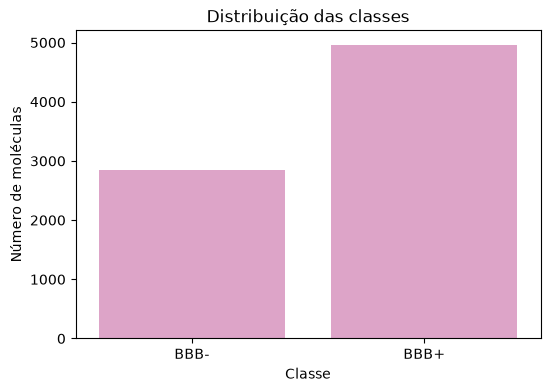

In [5]:
TARGET = "BBB+/BBB-"

plt.figure(figsize = (6 ,4))
sns.countplot(data = df_classificacao, x = TARGET, color = "#E69BCB")
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Número de moléculas")
plt.show()

Para averiguar se alguma molécula aparece mais de uma vez, veremos isso pelos seus SMILES.

In [32]:
print(f"SMILES duplicados: {df_classificacao["SMILES"].duplicated().sum()}")

SMILES duplicados: 0


Conforme é possível observar, todas as moléculas são únicas. 
O número de Nan's também é extremamente relevante:

In [7]:
print(f"Existem {df_classificacao.isna().all().sum()} atributos completamente vazios.")

Existem 76 atributos completamente vazios.


Alguns atributos estão vazios, muito provavelmente, pois determinados descritores não puderam ser calculados. Caso contrário, seria possível preencher as lacunas através dos SMILES das moléculas, uma vez que, segundo o artigo da Nature na qual ele foi publicado, os descritores foram todos calculados utilizando o módulo Mordred. Essa hipótese foi testada e, infelizmente, não obteve êxito.
Alguns descritores são muito específicos, de tal forma que existem 76 completamente vazios. Esses, serão descartados. No entanto, não é possível excluir as outras moléculas com atributos faltantes, pois todas possuem pelo menos um.

Para a criação dos algoritmos, foi criado um dataframe sem as colunas com identificadores e dados que poderiam denunciar o target, e sem colunas vazias. São definidos os atributos (descritores moldeculares) e o target a ser previsto (permeável ou impermeável à barreira hematoencefálica), além de preservar os SMILES em uma variável de modo a manter os índices correspondentes aos do dataset, pois eles serão necessários.

In [8]:
identificadores = ["NO.", "compound_name", "IUPAC_name", "CID", "logBB",
        "Inchi", "threshold", "reference", "group", "comments"]

#Criando dataframe para modelagem
df_modelagem = df_classificacao.drop(columns = identificadores).copy()
colunas_vazias = df_modelagem.columns[df_modelagem.isna().all()]
df_modelagem = df_modelagem.drop(columns = colunas_vazias)

#Separa os dados
ATRIBUTOS = df_modelagem.drop(columns = ["BBB+/BBB-", "SMILES"])
TARGET = df_modelagem["BBB+/BBB-"]
SMILES = df_modelagem["SMILES"].copy()

In [9]:
# Define-se a quantidade de ausentes por atributo
ausentes = ATRIBUTOS.isna().sum()
porcentagem_ausentes = ATRIBUTOS.isna().mean() * 100

print(f"""
    Atributos com valores ausentes: {(ausentes > 0).sum()}
    O total de valores ausentes é: {ausentes.sum()}.
    """)


    Atributos com valores ausentes: 804
    O total de valores ausentes é: 604601.
    


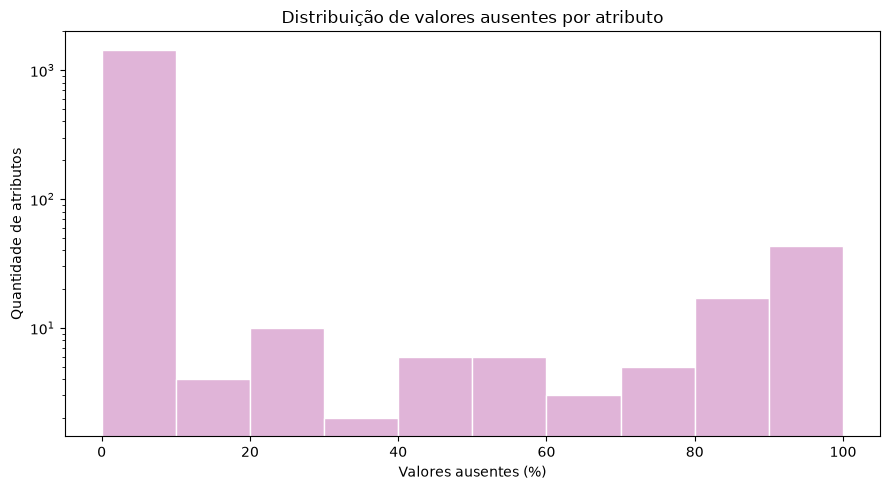

In [10]:
plt.figure(figsize=(9,5))

sns.histplot(
    porcentagem_ausentes,
    bins=10,
    edgecolor="white",
    color = "#D69BCB"
)

plt.xlabel("Valores ausentes (%)")
plt.ylabel("Quantidade de atributos")
plt.yscale("log")
plt.title("Distribuição de valores ausentes por atributo")
plt.tight_layout()
plt.show()

## Separação de treino e teste – (MurckoScaffold)

Para dividir os dados entre treino e teste, não é utilizada a função train_test_split comum. Em dados moleculares, é bastante provável que  existam moléculas muito semelhantes. Em uma divisão aleatória essas moléculas se dividem entre treino e de teste, e o modelo é avaliado com base em estruturas muito parecidas com as que ele já viu, o que o tornaria um modelo otimista. Não é uma avaliação muito justa dessa maneira, pois não identificaria se o modelo de fato aprendeu a encontrar padrões e a generalizar para moléculas novas.

Por isso, as moléculas foram agrupadas pelo Scaffold de Murcko, o esqueleto da molécula, que é uma decomposição dela em anéis e cadeias que os conectam, retirando as ramificações laterais. O seu objetivo é agrupar moléculas de uma mesma família estrutural, para garantir que nenhum scaffold de teste esteja no treino para evitar esse vazamento. Isso pode fazer as métricas de desempenho serem mais conservadoras.

 As moléculas sem anel foram tratadas como grupos individuais, usando o próprio SMILES como identificador para não correr o risco de criar um único grupo bem grande.

In [11]:
# Aqui se usa MurckoScaffold

SEMENTE_ALEATORIA = 1912

def scaffold(smiles):
    
    mol = Chem.MolFromSmiles(smiles) #Lê a molécula processando os SMILES
    
    if mol is None: 
        return None #Se o texto é um SMILES inválido, retorna None
        
    sc = MurckoScaffold.MurckoScaffoldSmiles(mol=mol) #Extrai o scaffold
    
# Sem anel -> Scaffold vazio e usa o próprio SMILES
    if sc != "":
        return sc
    else:
        return smiles

# Calcula Scaffolds para todas
df_modelagem["scaffold"] = df_modelagem["SMILES"].apply(scaffold)

# Remove e os SMILES inválidos
df_modelagem = df_modelagem.dropna(subset=["scaffold"]).copy()
grupos = df_modelagem["scaffold"].astype("category").cat.codes


[02:48:33] Explicit valence for atom # 10 C, 4, is greater than permitted
[02:48:36] Explicit valence for atom # 10 C, 4, is greater than permitted


É válido ressaltar que o scaffold não é a melhor técnica da quimioinformática para realizar o agrupamento de moléculas, por conta do seu próprio funcionamento de delimitação do esqueleto, moléculas parecidas ainda assim podem ficar em scaffolds diferentes e, utilizando diferentes abordagens, os scaffolds obtidos podem ser diferentes.
Ele é alvo de críticas pela comunidade, mas, ainda assim é amplamente utilizado. Para o escopo do projeto, ele é suficiente. Caso contrário, seria necessário adicionar mais camadas de complexidade, transformações diferentes e cálculos.

A separação entre treino e teste foi realizada com o GroupShuffleSplit, reservando 10% para teste, e a validação cruzada utilizada na otimização foi o StratifiedGroupKFold, porque ele respeita os mesmos grupos e preserva a proporção de BBB+ e BBB-.

In [12]:
# Aqui se usa GroupShuffleSplit
# Divisão em treino e teste baseada em scaffolds

gss = GroupShuffleSplit(
    n_splits = 1,
    test_size = 0.1,
    random_state = SEMENTE_ALEATORIA
)

indices_treino, indices_teste = next(
    gss.split(
        df_modelagem[ATRIBUTOS.columns],
        df_modelagem[TARGET.name],
        groups = grupos
    )
)

df_treino = df_modelagem.iloc[indices_treino]
df_teste = df_modelagem.iloc[indices_teste]

X_treino, y_treino = df_treino[ATRIBUTOS.columns], df_treino[TARGET.name]
X_teste, y_teste = df_teste[ATRIBUTOS.columns], df_teste[TARGET.name]

In [13]:
NUM_FOLDS = 10

grupos_treino = df_treino["scaffold"]
cv = StratifiedGroupKFold(n_splits = NUM_FOLDS, shuffle = True, random_state = SEMENTE_ALEATORIA)

## Modelo Baseline

In [14]:
# Aqui se usa DummyClassifier

modelo_baseline = DummyClassifier()
modelo_baseline.fit(X_treino, y_treino)

DummyClassifier()

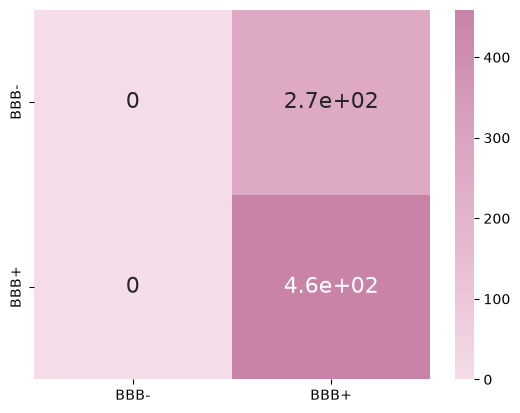

In [15]:
# Aqui se usa confusion_matrix
ordem_labels = df_modelagem["BBB+/BBB-"].unique().tolist()

y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

# Aquis se usa LinearSegmentedColormap

paleta = LinearSegmentedColormap.from_list(
    "soft_scientific",
    [ "#F4DCE8",
    "#E8BBD0",
    "#D9A3C1",
    "#C982A8",]
)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap = paleta);

In [16]:
# Aqui se usa accuracy_score

acuracia = accuracy_score(y_verdadeiro, y_previsao)

print(f"Acurácia = {(acuracia*100):.2f}%")

Acurácia = 63.22%


In [17]:
X = X_treino.to_numpy(dtype=float)
print("NaNs:", np.isnan(X).sum())

NaNs: 549450


## K-Nearest Neighbors

### Modelo e espaço de busca

In [18]:
def cria_selecao(trial):
    return SelectKBest(score_func = f_classif,
                       k = trial.suggest_int("k", 20, 500))

In [19]:
def cria_instancia_knn(trial):
    """Cria uma instância do modelo.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 200, log = True),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan"]),
    }
         
    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        StandardScaler(),
        KNeighborsClassifier(**parametros)
    )

    return modelo

In [20]:
def funcao_objetivo(trial, X, y):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_instancia_knn(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="roc_auc",
        cv=cv,
        groups = grupos_treino,
        n_jobs = -2,
    )

    return metricas.mean()

In [21]:
NOME_DO_ESTUDO = "estudo_knn"

objeto_de_estudo_knn = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [22]:
funcao_objetivo_parcial_knn = partial(
    funcao_objetivo, X=X_treino, y=y_treino
)

In [33]:
NUM_TENTATIVAS =100

objeto_de_estudo_knn.optimize(funcao_objetivo_parcial_knn, n_trials=NUM_TENTATIVAS)

In [25]:
df_resultado_knn = objeto_de_estudo_knn.trials_dataframe()

df_resultado_knn

,number,value,datetime_start,datetime_complete,duration,params_k,params_metric,params_n_neighbors,params_weights,state
0,0,NaN,2026-11-18 02:51:25.358547,2026-11-18 02:51:55.794250,0 days 00:00:30.435703,368,manhattan,8,distance,FAIL
1,1,0.889448,2026-11-18 02:51:55.853609,2026-11-18 02:52:14.382227,0 days 00:00:18.528618,363,euclidean,11,distance,COMPLETE
2,2,0.880484,2026-11-18 02:52:14.438957,2026-11-18 02:52:25.332268,0 days 00:00:10.893311,155,euclidean,54,uniform,COMPLETE
3,3,0.866410,2026-11-18 02:52:25.379731,2026-11-18 02:52:36.736374,0 days 00:00:11.356643,244,euclidean,5,distance,COMPLETE
4,4,0.888902,2026-11-18 02:52:36.777820,2026-11-18 02:52:47.039093,0 days 00:00:10.261273,54,manhattan,13,distance,COMPLETE
...,...,...,...,...,...,...,...,...,...,...
95,95,0.892890,2026-11-18 03:09:36.198773,2026-11-18 03:09:45.978896,0 days 00:00:09.780123,279,euclidean,21,distance,COMPLETE
96,96,0.892427,2026-11-18 03:09:46.041729,2026-11-18 03:09:56.412267,0 days 00:00:10.370538,332,euclidean,25,distance,COMPLETE
97,97,0.890505,2026-11-18 03:09:56.475720,2026-11-18 03:10:06.466334,0 days 00:00:09.990614,302,euclidean,14,distance,COMPLETE
98,98,0.892789,2026-11-18 03:10:06.538326,2026-11-18 03:10:18.064291,0 days 00:00:11.525965,289,euclidean,18,distance,COMPLETE


In [26]:
melhor_trial = objeto_de_estudo_knn.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Número do melhor trial: 54
Parâmetros do melhor trial: {'n_neighbors': 20, 'weights': 'distance', 'metric': 'euclidean', 'k': 304}


In [27]:
y_treino = (y_treino == "BBB+").astype(int)
y_teste = (y_teste == "BBB+").astype(int)

melhor_modelo = cria_instancia_knn(optuna.trial.FixedTrial(objeto_de_estudo_knn.best_params))
melhor_modelo.fit(X_treino, y_treino)

y_proba_knn = melhor_modelo.predict_proba(X_teste)[:, 1]
y_previsao_knn = melhor_modelo.predict(X_teste)


print(f"ROC-AUC: {roc_auc_score(y_teste, y_proba_knn)}")

C:\venvs\ilumpy\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\venvs\ilumpy\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\venvs\ilumpy\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\venvs\ilumpy\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\venvs\ilumpy\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
            

ROC-AUC: 0.91452677617031


In [34]:
print(f"ROC-AUC da validação cruzada: {objeto_de_estudo_knn.best_value}")

ROC-AUC da validação cruzada: 0.8943509962601288


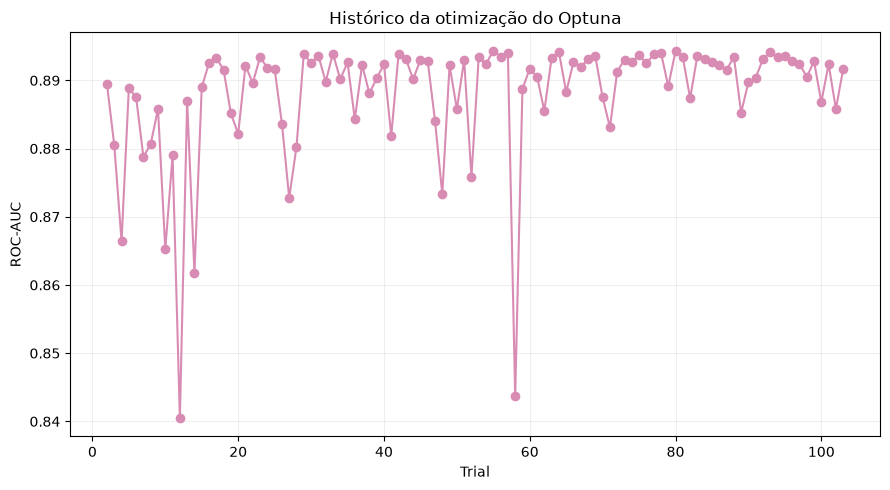

In [35]:
resultados = [trial.value for trial in objeto_de_estudo_knn.trials]

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(resultados) + 1), resultados, "o-", color="#D98CB3")

plt.xlabel("Trial")
plt.ylabel("ROC-AUC")
plt.title("Histórico da otimização do Optuna")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

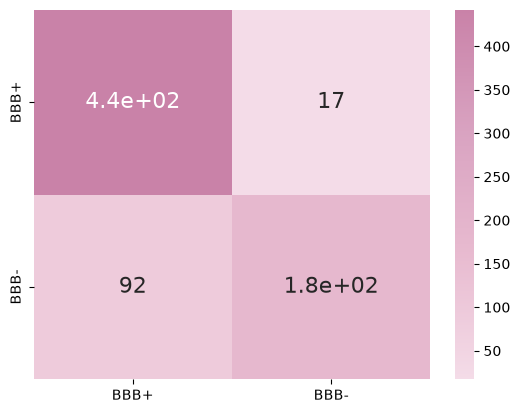

In [36]:
# Aqui se usa confusion_matrix
ordem_labels = [1, 0]
nomes = ["BBB+", "BBB-"]

matriz_conf = confusion_matrix(y_teste, y_previsao_knn, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, index = nomes, columns = nomes)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap = paleta);

## Regressão Logística

In [38]:
def cria_instancia_rl(trial):
    """Cria uma instância do modelo.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    parametros = {
        # espaço de busca
        "C": trial.suggest_float("c", 0.001, 100, log = True),
        "max_iter": 5000,
        "random_state": SEMENTE_ALEATORIA,
        
    }
         
    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        StandardScaler(),
        LogisticRegression(**parametros)
    )

    return modelo

In [39]:
def funcao_objetivo(trial, X, y):
    """Função objetivo do optuna
    """

    modelo = cria_instancia_rl(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="roc_auc",
        cv=cv,
        groups = grupos_treino,
        n_jobs = -2,
    )

    return metricas.mean()

In [40]:
NOME_DO_ESTUDO = "rlog_estudo"

objeto_de_estudo_rlog = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [41]:
funcao_objetivo_parcial_rlog = partial(
    funcao_objetivo, X=X_treino, y=y_treino
)

In [42]:
NUM_TENTATIVAS = 100

objeto_de_estudo_rlog.optimize(funcao_objetivo_parcial_rlog, n_trials=NUM_TENTATIVAS)

In [43]:
df_resultado_rlog = objeto_de_estudo_rlog.trials_dataframe()

df_resultado_rlog

,number,value,datetime_start,datetime_complete,duration,params_c,params_k,state
0,0,0.888143,2026-11-18 02:29:41.356311,2026-11-18 02:29:58.447192,0 days 00:00:17.090881,0.155283,492,COMPLETE
1,1,0.887531,2026-11-18 03:23:33.856472,2026-11-18 03:23:47.153531,0 days 00:00:13.297059,0.248849,306,COMPLETE
2,2,0.865825,2026-11-18 03:23:47.219796,2026-11-18 03:23:56.396081,0 days 00:00:09.176285,0.001708,116,COMPLETE
3,3,0.889222,2026-11-18 03:23:56.428859,2026-11-18 03:24:10.414202,0 days 00:00:13.985343,0.397263,460,COMPLETE
4,4,0.888199,2026-11-18 03:24:10.480190,2026-11-18 03:24:29.652941,0 days 00:00:19.172751,1.416866,458,COMPLETE
...,...,...,...,...,...,...,...,...
96,96,0.890739,2026-11-18 03:44:17.711017,2026-11-18 03:44:27.731871,0 days 00:00:10.020854,0.098207,414,COMPLETE
97,97,0.888038,2026-11-18 03:44:27.776038,2026-11-18 03:44:37.020209,0 days 00:00:09.244171,0.021284,421,COMPLETE
98,98,0.890413,2026-11-18 03:44:37.054898,2026-11-18 03:44:46.527887,0 days 00:00:09.472989,0.083995,415,COMPLETE
99,99,0.885906,2026-11-18 03:44:46.567751,2026-11-18 03:44:54.647974,0 days 00:00:08.080223,0.105419,284,COMPLETE


In [44]:
melhor_trial = objeto_de_estudo_rlog.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Número do melhor trial: 71
Parâmetros do melhor trial: {'c': 0.13472136497964043, 'k': 453}


In [45]:
melhor_modelo = cria_instancia_rl(optuna.trial.FixedTrial(objeto_de_estudo_rlog.best_params))
melhor_modelo.fit(X_treino, y_treino)

y_proba_rlog = melhor_modelo.predict_proba(X_teste)[:, 1]
y_previsao_rlog = melhor_modelo.predict(X_teste)


print(f"ROC-AUC: {roc_auc_score(y_teste, y_proba_rlog)}")

C:\venvs\ilumpy\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


ROC-AUC: 0.8817654402585005


In [46]:
print(f"ROC-AUC da validação cruzada: {objeto_de_estudo_rlog.best_value}")

ROC-AUC da validação cruzada: 0.890926259337769


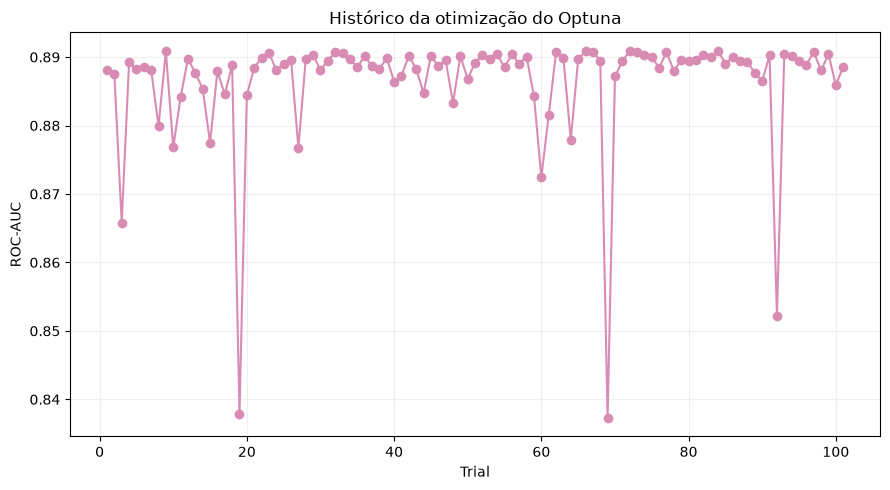

In [47]:
resultados = [trial.value for trial in objeto_de_estudo_rlog.trials]

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(resultados) + 1), resultados, "o-", color="#D98CB3")

plt.xlabel("Trial")
plt.ylabel("ROC-AUC")
plt.title("Histórico da otimização do Optuna")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

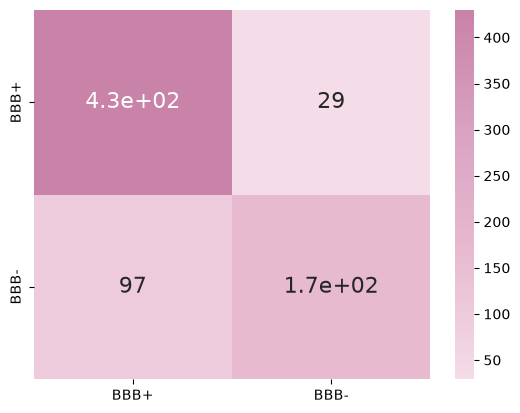

In [48]:
# Aqui se usa confusion_matrix

matriz_conf = confusion_matrix(y_teste, y_previsao_rlog, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, index = nomes, columns = nomes)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap = paleta);

## Árvore de Decisão

In [82]:
def cria_instancia_arvore(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    
    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]), #critério de split
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 200, log = True),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-5, 1e-2, log=True),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        DecisionTreeClassifier(**parametros)
    )

    return modelo

In [83]:
def funcao_objetivo(trial, X, y):
    """Função objetivo do optuna
    """

    modelo = cria_instancia_arvore(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="roc_auc",
        cv=cv,
        groups = grupos_treino,
        n_jobs = -2,
    )

    return metricas.mean()

In [84]:
NOME_DO_ESTUDO = "estudo_arvore"

objeto_de_estudo_arvore = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [85]:
funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino
)

In [86]:
NUM_TENTATIVAS = 100

objeto_de_estudo_arvore.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [87]:
df_resultado_arvore = objeto_de_estudo_arvore.trials_dataframe()

df_resultado_arvore

,number,value,datetime_start,datetime_complete,duration,params_ccp_alpha,params_criterion,params_k,params_max_depth,params_max_features,params_min_samples_leaf,state
0,0,0.852871,2026-11-18 04:58:58.660865,2026-11-18 04:59:08.558525,0 days 00:00:09.897660,0.003001,entropy,106,7,0.525952,22,COMPLETE
1,1,0.860306,2026-11-18 04:59:08.609863,2026-11-18 04:59:21.779187,0 days 00:00:13.169324,0.000066,gini,428,11,0.716842,63,COMPLETE
2,2,0.841278,2026-11-18 04:59:21.849188,2026-11-18 04:59:33.109457,0 days 00:00:11.260269,0.001672,entropy,238,10,0.651952,5,COMPLETE
3,3,0.836536,2026-11-18 04:59:33.153936,2026-11-18 04:59:42.388382,0 days 00:00:09.234446,0.000076,gini,55,8,0.588240,21,COMPLETE
4,4,0.828662,2026-11-18 04:59:42.451313,2026-11-18 04:59:51.151018,0 days 00:00:08.699705,0.000023,gini,50,15,0.186220,17,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.845979,2026-11-18 05:20:06.247765,2026-11-18 05:20:19.797115,0 days 00:00:13.549350,0.000048,gini,483,14,0.731313,40,COMPLETE
96,96,0.853475,2026-11-18 05:20:19.845133,2026-11-18 05:20:33.225606,0 days 00:00:13.380473,0.000344,entropy,491,13,0.697773,64,COMPLETE
97,97,0.854317,2026-11-18 05:20:33.257478,2026-11-18 05:20:47.768468,0 days 00:00:14.510990,0.000171,entropy,500,12,0.854438,27,COMPLETE
98,98,0.858815,2026-11-18 05:20:47.830416,2026-11-18 05:21:02.042618,0 days 00:00:14.212202,0.000530,entropy,445,15,0.822072,55,COMPLETE


In [88]:
melhor_trial = objeto_de_estudo_arvore.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

Número do melhor trial: 43
Parâmetros do melhor trial: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 63, 'max_features': 0.9594420729619346, 'ccp_alpha': 0.00020364613384412205, 'k': 474}


In [89]:
melhor_modelo = cria_instancia_arvore(optuna.trial.FixedTrial(objeto_de_estudo_arvore.best_params))
melhor_modelo.fit(X_treino, y_treino)

y_proba_rlog = melhor_modelo.predict_proba(X_teste)[:, 1]
y_previsao_rlog = melhor_modelo.predict(X_teste)


print(f"ROC-AUC: {roc_auc_score(y_teste, y_proba_rlog)}")

ROC-AUC: 0.8825854936231671


In [90]:
print(f"ROC-AUC da validação cruzada: {objeto_de_estudo_arvore.best_value}")

ROC-AUC da validação cruzada: 0.8685941235778367


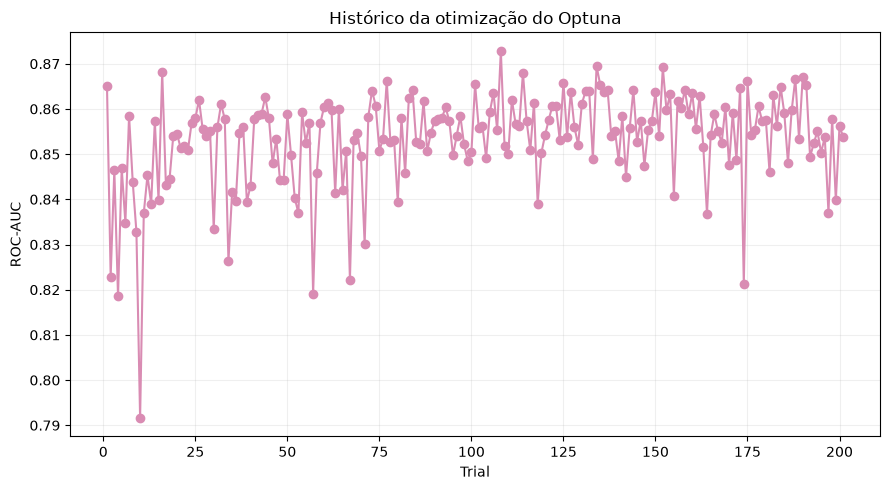

In [62]:
resultados = [trial.value for trial in objeto_de_estudo_arvore.trials]

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(resultados) + 1), resultados, "o-", color="#D98CB3")

plt.xlabel("Trial")
plt.ylabel("ROC-AUC")
plt.title("Histórico da otimização do Optuna")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

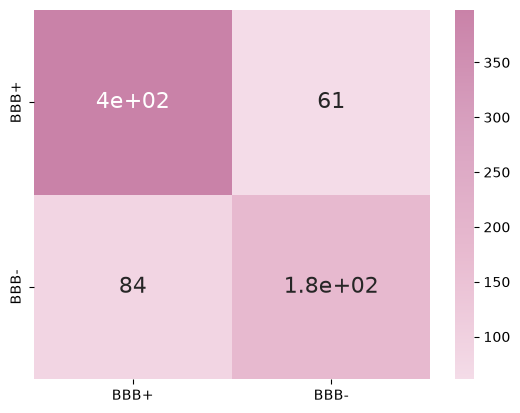

In [63]:
# Aqui se usa confusion_matrix

matriz_conf = confusion_matrix(y_teste, y_previsao_rlog, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, index = nomes, columns = nomes)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap = paleta);

## Floresta Aleatória

In [97]:
def cria_instancia_floresta(trial):
    """Cria uma instância do modelo de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    
    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000, log=True),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]), #critério de split
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        # argumentos fixos
        "n_jobs": -2,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        RandomForestClassifier(**parametros)
    )

    return modelo

In [98]:
def funcao_objetivo(trial, X, y):
    """Função objetivo do optuna
    """

    modelo = cria_instancia_arvore(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="roc_auc",
        cv=cv,
        groups = grupos_treino,
        n_jobs = -2,
    )

    return metricas.mean()

In [99]:
NOME_DO_ESTUDO = "estudo_da_floresta"

objeto_de_estudo_floresta = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [100]:
funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino
)

In [ ]:
NUM_TENTATIVAS = 100

objeto_de_estudo_floresta.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [ ]:
df_floresta = objeto_de_estudo_floresta.trials_dataframe()
df_floresta

In [ ]:
melhor_trial = objeto_de_estudo_floresta.best_trial

print(f"Número do melhor trial: {melhor_trial.number}")
print(f"Parâmetros do melhor trial: {melhor_trial.params}")

In [ ]:
melhor_modelo = cria_instancia_floresta(optuna.trial.FixedTrial(objeto_de_estudo_floresta.best_params))
melhor_modelo.fit(X_treino, y_treino)

y_proba_floresta = melhor_modelo.predict_proba(X_teste)[:, 1]
y_previsao_floresta = melhor_modelo.predict(X_teste)


print(f"ROC-AUC: {roc_auc_score(y_teste, y_proba_floresta)}")

In [74]:
print(objeto_de_estudo_floresta.study_name)       # qual estudo é esse?
print(objeto_de_estudo_floresta.best_params)      # tem n_estimators?

floresta_estudo
{'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 26, 'max_features': 0.8297100615816527, 'ccp_alpha': 0.0039941317543472155, 'k': 283}


In [ ]:
## C

## Apêndice I - Nota sobre a abordagem de classificação

A proposta inicial desse trabalho era desenvolver modelos de regressão para prever os valores quantitativos de permeabilidade na barreira hematoencefálica (logBB), utilizando o dataset "B3DB_regression_extended.tsv.gz", do banco Blood-Brain Barrier Dataset (B3DB).

No entanto, já no primeiro modelo o RMSE obtido foi de 0,7 unidades de logBB. Isso significa que o modelo errava na razão entre as concentrações cerebrais e sanguíneas por um fator de 5 vezes (já que $10^{0,7}\approx 5\$). O volume de dados do dataset de regressão era um tanto limitado, com pouco mais de 1000 compostos, o que dificulta o aprendizado de relações mais complexas, e havia vazamento de dados no código, cuja estrutura se emaranhava sem direção. O dataset foi trocado pelo de classificação e o trabalho reiniciado, motivo pelo qual a versão inicial do arquivo não corresponde às versões finais.

https://medium.com/data-hackers/como-selecionar-as-melhores-features-para-seu-modelo-de-machine-learning-faf74e357913

https://www.nature.com/articles/s41597-021-01069-5

https://www.nature.com/articles/s41598-024-66897-y?fromPaywallRec=false

https://www.sciencedirect.com/topics/medicine-and-dentistry/molecular-descriptor

https://www.datacamp.com/pt/tutorial/auc